# Putative neuronal populations and cocaine responses

This notebook reproduces the putative-cell classification and applies the Figure 2 response-classification rules to each putative population in the vehicle (VEH) and cocaine (COC) groups.

In [3]:
from pathlib import Path
import collections
import pickle
import warnings

import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from scipy import stats
from scipy.signal import convolve, windows
from scipy.stats import mannwhitneyu, shapiro

## Load the processed unit data

In [4]:
# Locate the data file whether Jupyter starts in the repository root
# or in the notebook directory.
project_candidates = (Path.cwd(), *Path.cwd().parents)
project_root = next(
    (path for path in project_candidates if (path / "data" / "NAC" / "1468.pkl").is_file()),
    None,
)
if project_root is None:
    raise FileNotFoundError("Could not locate data/NAC/1468.pkl from the current directory.")

data_file = project_root / "data" / "NAC" / "1468.pkl"

# The pickle contains twelve arrays in a fixed order and must only be loaded
# from this trusted repository.
with data_file.open("rb") as stream:
    half_width = pickle.load(stream)
    proportion_long_isi = pickle.load(stream)
    post_spike_suppression = pickle.load(stream)
    animal_id = pickle.load(stream)
    shank_id = pickle.load(stream)
    unit_id = pickle.load(stream)
    spike_duration_s = pickle.load(stream)
    mean_firing_rate = pickle.load(stream)
    secondary_firing_rate = pickle.load(stream)
    spike_times = pickle.load(stream)
    autocorrelations = pickle.load(stream)
    waveforms = pickle.load(stream)

print(f"Loaded {spike_duration_s.shape[0]} units from {data_file.name}.")

Loaded 1468 units from 1468.pkl.


## Analysis parameters

In [5]:
region = "NAc"
baseline_duration_s = 30 * 60
injection_time_s = 60 * 60
injection_gap_s = 60
bin_width_s = 5

# The interval includes 30 min before injection, a 1 min injection gap,
# and 30 min after injection, matching the Figure 2 analysis.
time_edges_s = np.arange(
    injection_time_s - baseline_duration_s,
    injection_time_s + baseline_duration_s + injection_gap_s + bin_width_s,
    bin_width_s,
)
time_axis_min = (time_edges_s[:-1] - injection_time_s) / 60

vehicle_color = "tab:blue"
cocaine_color = "tab:orange"
response_colors = ["#d62728", "#3b5ba9", "#bfbfbf"]

plt.rcParams.update({"font.size": 16})
plt.rcParams["axes.spines.right"] = False
plt.rcParams["axes.spines.top"] = False

## Classify putative neuronal populations

In [6]:
# Convert spike duration from seconds to microseconds. The thresholds below
# reproduce the original putative-cell classification without modification.
spike_duration_us = spike_duration_s * 1_000_000

population_masks = {
    "FSI": (spike_duration_us <= 400) & (proportion_long_isi <= 0.1),
    "UIN": (spike_duration_us <= 400) & (proportion_long_isi > 0.1),
    "MSN": (spike_duration_us > 400) & (post_spike_suppression < 40),
    "TAN": (spike_duration_us > 400) & (post_spike_suppression >= 40),
}
population_colors = {
    "FSI": "gray",
    "UIN": "orange",
    "MSN": "red",
    "TAN": "green",
}

membership_count = sum(mask.astype(int) for mask in population_masks.values())
if not np.all(membership_count == 1):
    raise ValueError("The population masks are not mutually exclusive and exhaustive.")

for population, mask in population_masks.items():
    print(f"{population}: {np.count_nonzero(mask)} units")

FSI: 57 units
UIN: 57 units
MSN: 1211 units
TAN: 143 units


## Putative-population feature space

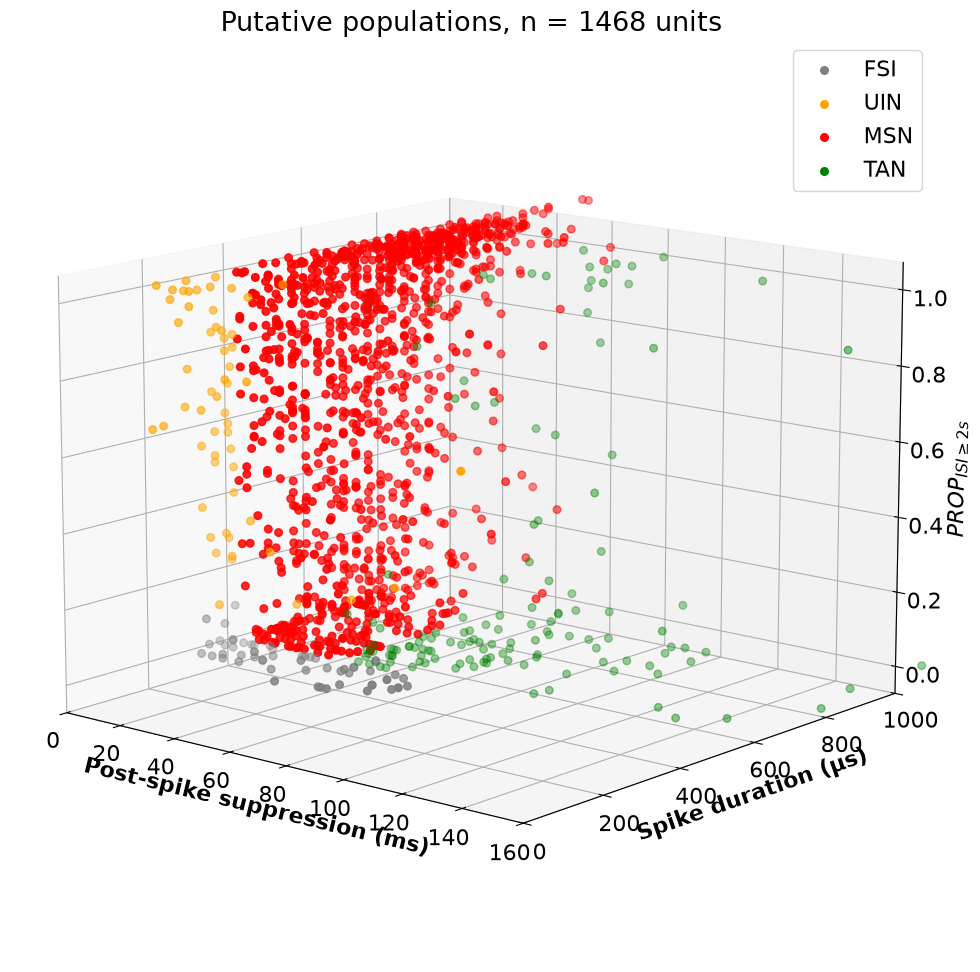

In [7]:
fig = plt.figure(figsize=(10, 10))
ax = fig.add_subplot(projection="3d")

for population, mask in population_masks.items():
    ax.scatter3D(
        post_spike_suppression[mask],
        spike_duration_us[mask],
        proportion_long_isi[mask],
        s=30,
        label=population,
        color=population_colors[population],
    )

ax.set_xlim(0, 160)
ax.set_ylim(0, 1000)
ax.set_xlabel("Post-spike suppression (ms)", fontweight="bold")
ax.set_ylabel("Spike duration (µs)", fontweight="bold")
ax.set_zlabel(r"$PROP_{ISI \geq 2 s}$", fontweight="bold")
ax.set_title(f"Putative populations, n = {len(spike_duration_us)} units")
ax.view_init(13, -50)
ax.legend()
plt.tight_layout()
plt.show()

## Average waveforms and autocorrelations

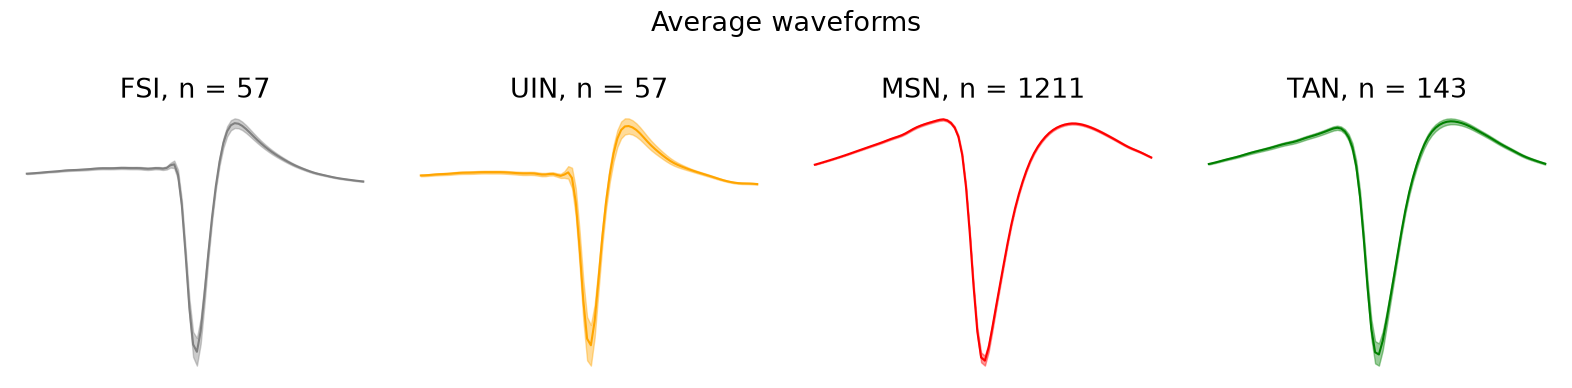

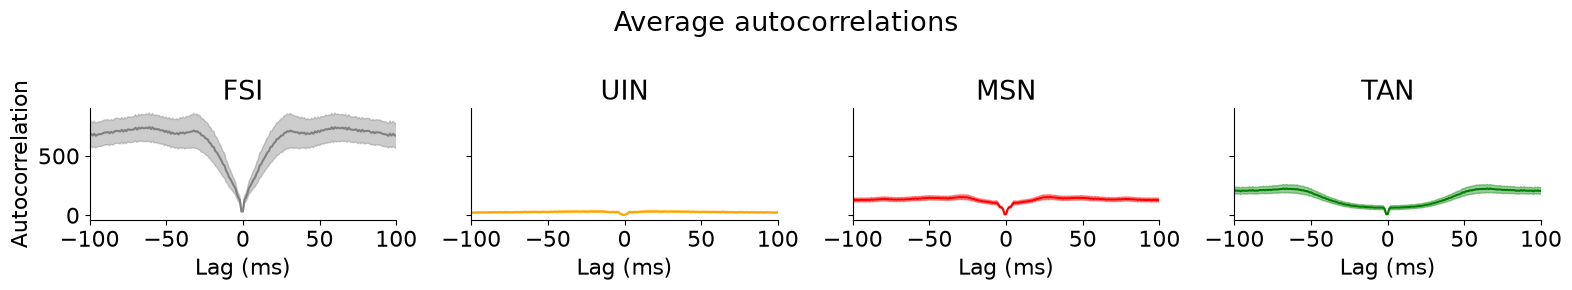

In [8]:
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, (population, mask) in zip(axes, population_masks.items()):
    population_waveforms = np.asarray(waveforms[mask].tolist(), dtype=float)
    average_waveform = np.mean(population_waveforms, axis=0)
    waveform_sem = stats.sem(population_waveforms, axis=0)
    ax.plot(average_waveform, color=population_colors[population])
    ax.fill_between(
        np.arange(average_waveform.size),
        average_waveform - waveform_sem,
        average_waveform + waveform_sem,
        color=population_colors[population],
        alpha=0.4,
    )
    ax.set_title(f"{population}, n = {np.count_nonzero(mask)}")
    ax.set_axis_off()
fig.suptitle("Average waveforms")
plt.tight_layout()
plt.show()

acf_edges_ms = np.arange(-30_000, 30_000 + 30, 30) * 1_000 / 30_000
fig, axes = plt.subplots(1, 4, figsize=(16, 3), sharey=True)
for ax, (population, mask) in zip(axes, population_masks.items()):
    population_acf = np.asarray(autocorrelations[mask].tolist(), dtype=float)
    average_acf = np.mean(population_acf, axis=0)
    acf_sem = stats.sem(population_acf, axis=0)
    ax.plot(acf_edges_ms[:-1], average_acf, color=population_colors[population])
    ax.fill_between(
        acf_edges_ms[:-1],
        average_acf - acf_sem,
        average_acf + acf_sem,
        color=population_colors[population],
        alpha=0.4,
    )
    ax.set_xlim(-100, 100)
    ax.set_title(population)
    ax.set_xlabel("Lag (ms)")
axes[0].set_ylabel("Autocorrelation")
fig.suptitle("Average autocorrelations")
plt.tight_layout()
plt.show()

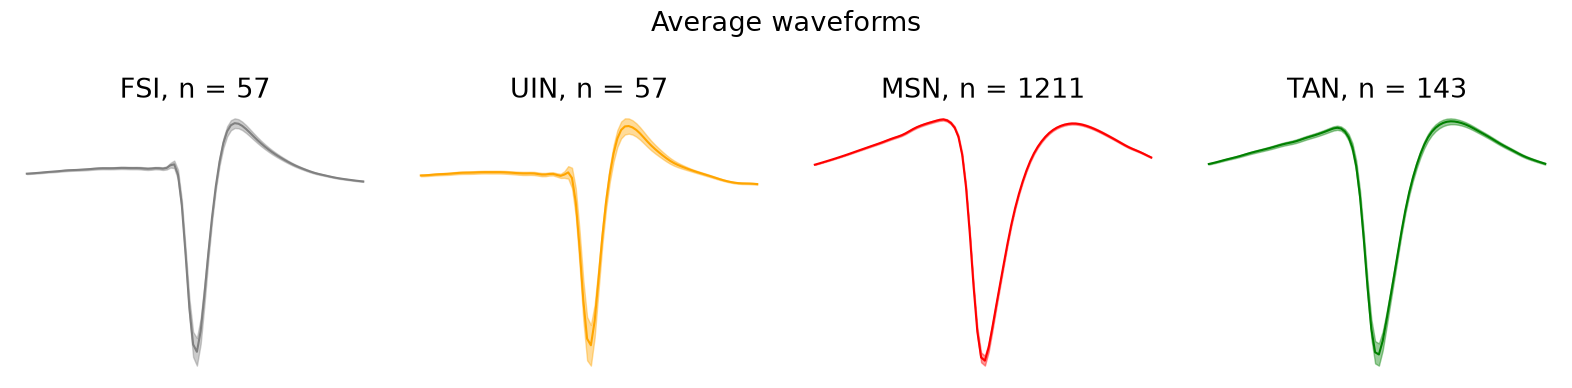

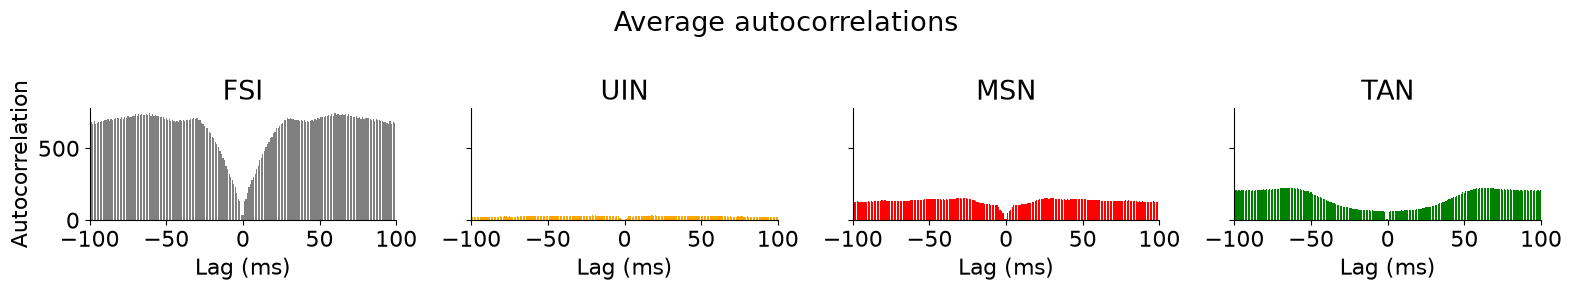

In [9]:
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, (population, mask) in zip(axes, population_masks.items()):
    population_waveforms = np.asarray(waveforms[mask].tolist(), dtype=float)
    average_waveform = np.mean(population_waveforms, axis=0)
    waveform_sem = stats.sem(population_waveforms, axis=0)
    ax.plot(average_waveform, color=population_colors[population])
    ax.fill_between(
        np.arange(average_waveform.size),
        average_waveform - waveform_sem,
        average_waveform + waveform_sem,
        color=population_colors[population],
        alpha=0.4,
    )
    ax.set_title(f"{population}, n = {np.count_nonzero(mask)}")
    ax.set_axis_off()
fig.suptitle("Average waveforms")
plt.tight_layout()
plt.show()

acf_edges_ms = np.arange(-30_000, 30_000 + 30, 30) * 1_000 / 30_000
fig, axes = plt.subplots(1, 4, figsize=(16, 3), sharey=True)
for ax, (population, mask) in zip(axes, population_masks.items()):
    population_acf = np.asarray(autocorrelations[mask].tolist(), dtype=float)
    average_acf = np.mean(population_acf, axis=0)
    acf_sem = stats.sem(population_acf, axis=0)
    ax.bar(acf_edges_ms[:-1], average_acf, color=population_colors[population])
    # ax.fill_between(
    #     acf_edges_ms[:-1],
    #     average_acf - acf_sem,
    #     average_acf + acf_sem,
    #     color=population_colors[population],
    #     alpha=0.4,
    # )
    ax.set_xlim(-100, 100)
    ax.set_title(population)
    ax.set_xlabel("Lag (ms)")
axes[0].set_ylabel("Autocorrelation")
fig.suptitle("Average autocorrelations")
plt.tight_layout()
plt.show()

## Putative-population composition

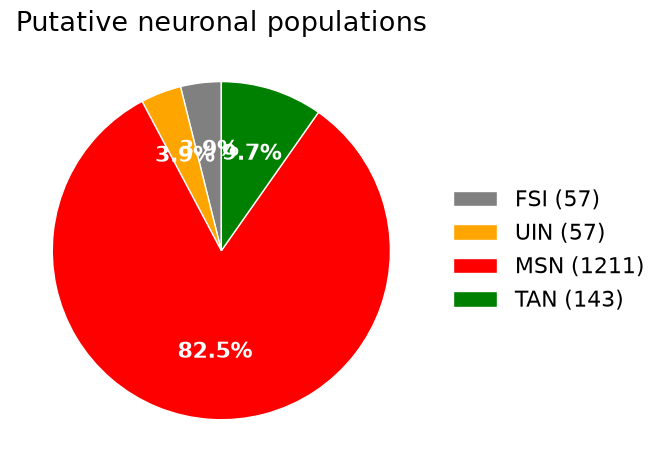

In [10]:
population_counts = {
    population: int(np.count_nonzero(mask))
    for population, mask in population_masks.items()
}

fig, ax = plt.subplots(figsize=(7, 5))
wedges, _, percentage_texts = ax.pie(
    population_counts.values(),
    colors=[population_colors[name] for name in population_counts],
    startangle=90,
    autopct="%1.1f%%",
    wedgeprops={"edgecolor": "white"},
)
ax.legend(
    wedges,
    [f"{name} ({count})" for name, count in population_counts.items()],
    loc="center left",
    bbox_to_anchor=(1.0, 0.5),
    frameon=False,
)
plt.setp(percentage_texts, color="white", fontweight="bold")
ax.set_title("Putative neuronal populations")
ax.set_aspect("equal")
plt.tight_layout()
plt.show()

## Compute firing-rate matrices

In [11]:
def compute_firing_rate_matrix(selected_spike_times):
    """Return a neuron-by-time matrix of firing rates in 5 s bins."""
    firing_rates = np.zeros((len(selected_spike_times), len(time_edges_s) - 1))
    for neuron_index, neuron_spikes in enumerate(selected_spike_times):
        counts, _ = np.histogram(neuron_spikes, bins=time_edges_s)
        firing_rates[neuron_index] = counts / bin_width_s
    return firing_rates


group_labels = np.asarray([str(value)[:3] for value in animal_id])
group_masks = {
    "VEH": group_labels == "VEH",
    "COC": group_labels == "COC",
}

firing_rate_matrices = {}
for population, population_mask in population_masks.items():
    firing_rate_matrices[population] = {}
    for group, group_mask in group_masks.items():
        combined_mask = population_mask & group_mask
        matrix = compute_firing_rate_matrix(spike_times[combined_mask])
        if matrix.size == 0:
            raise ValueError(f"No units found for {population} — {group}.")
        firing_rate_matrices[population][group] = matrix
        print(f"{population} — {group}: {matrix.shape[0]} units")

FSI — VEH: 15 units
FSI — COC: 42 units
UIN — VEH: 24 units
UIN — COC: 33 units
MSN — VEH: 648 units
MSN — COC: 563 units
TAN — VEH: 68 units
TAN — COC: 75 units


## Population firing-rate time courses

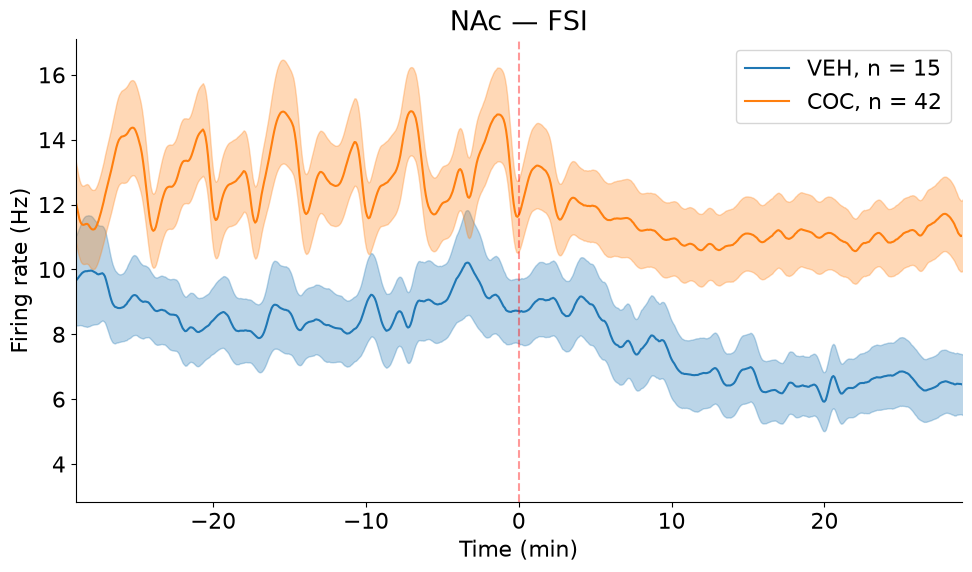

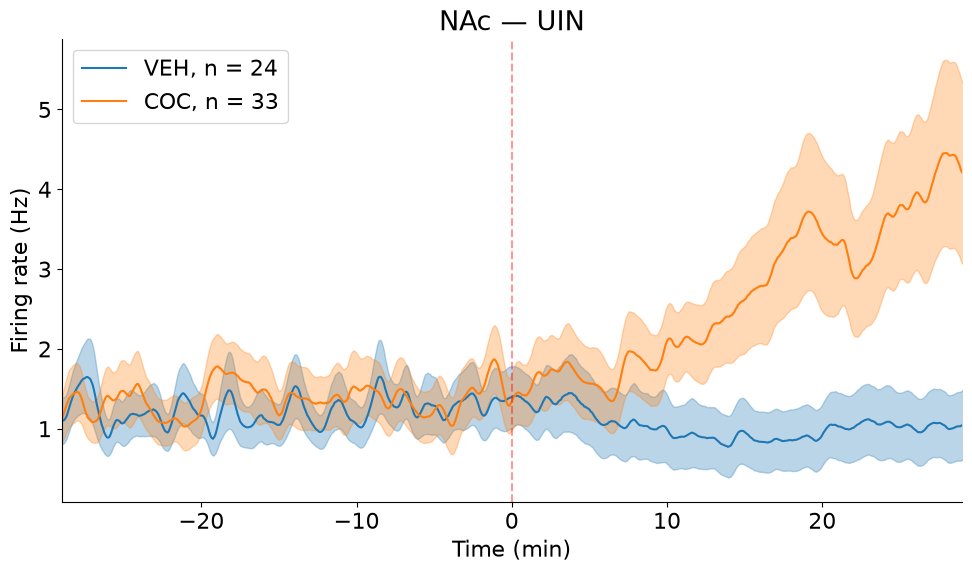

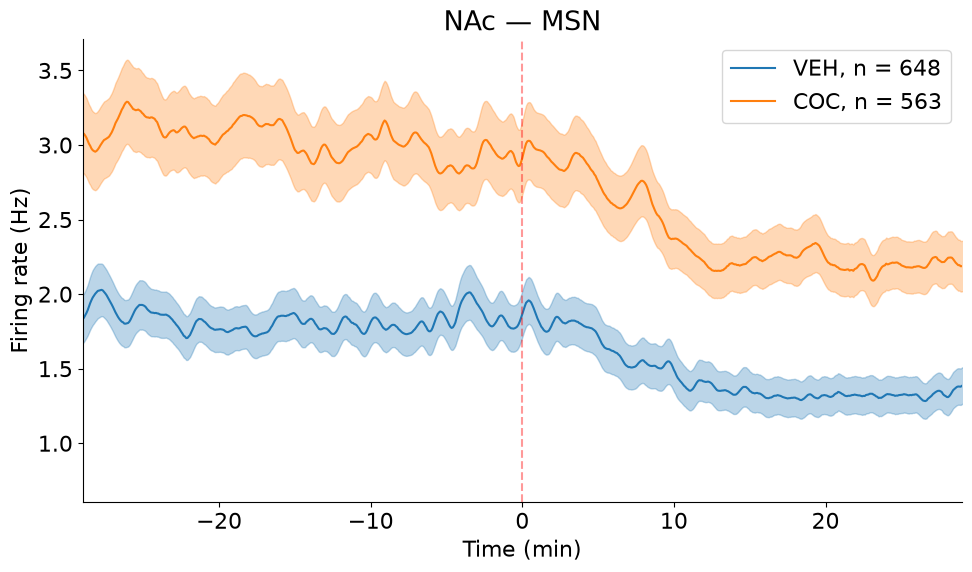

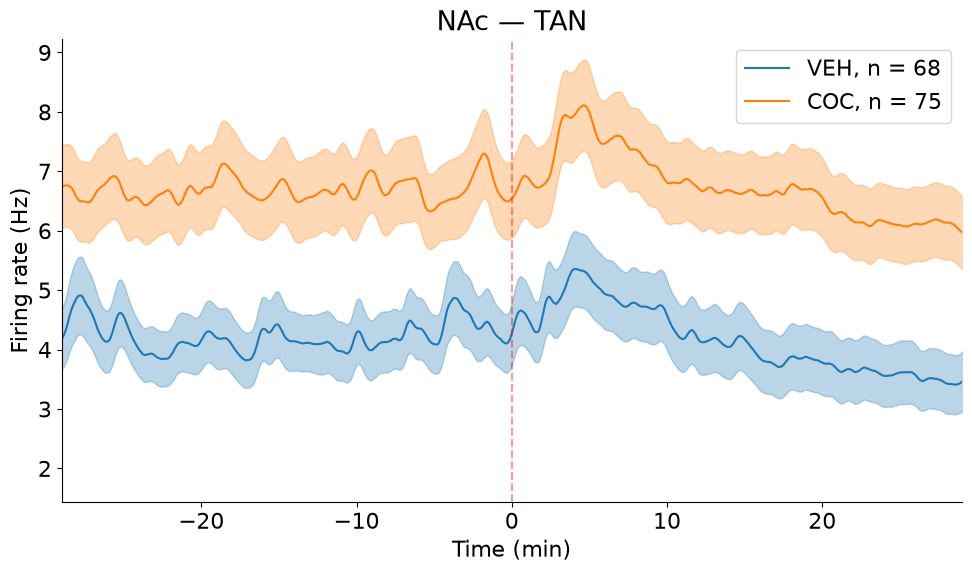

In [13]:
gaussian_window = windows.gaussian(4 * 3, 3)
gaussian_kernel = gaussian_window / gaussian_window.sum()

def plot_population_time_course(population):
    """Plot the mean firing-rate time course for VEH and COC units."""
    fig, ax = plt.subplots(figsize=(10, 6))
    for group, color in (("VEH", vehicle_color), ("COC", cocaine_color)):
        matrix = firing_rate_matrices[population][group]
        mean_rate = np.mean(matrix, axis=0)
        sem_rate = stats.sem(matrix, axis=0)
        smooth_mean = convolve(mean_rate, gaussian_kernel, mode="same")
        smooth_sem = convolve(sem_rate, gaussian_kernel, mode="same")
        ax.plot(time_axis_min, smooth_mean, color=color, label=f"{group}, n = {len(matrix)}")
        ax.fill_between(
            time_axis_min,
            smooth_mean - smooth_sem,
            smooth_mean + smooth_sem,
            color=color,
            alpha=0.3,
        )
    ax.axvline(0, color="red", linestyle="--", alpha=0.4)
    ax.set_xlim(-29, 29)
    ax.set(xlabel="Time (min)", ylabel="Firing rate (Hz)", title=f"{region} — {population}")
    ax.legend()
    plt.tight_layout()
    plt.show()

for population in population_masks:
    plot_population_time_course(population)

## Classify pre- versus post-injection responses

The following function intentionally preserves the Figure 2 rules: Shapiro tests are applied to each window, normally distributed windows use `ttest_ind`, other windows use `mannwhitneyu`, and `p < 0.05` determines increase or decrease.

In [14]:
def classify_responses(firing_rates):
    """Apply the original Figure 2 response-classification rules."""
    window_bins = int(baseline_duration_s / bin_width_s)
    classifications = []
    z_scores = []

    for neuron_rate in firing_rates:
        baseline = neuron_rate[:window_bins]
        after = neuron_rate[-window_bins:]
        baseline_mean = np.mean(baseline)
        baseline_std = np.std(baseline)

        # Preserve the original handling of constant baseline activity:
        # classify the response, but omit the undefined z-score row.
        if baseline_std != 0 and not np.isnan(baseline_std):
            z_scores.append((neuron_rate - baseline_mean) / baseline_std)

        with warnings.catch_warnings():
            warnings.simplefilter("ignore", RuntimeWarning)
            baseline_shapiro_p = shapiro(baseline).pvalue
            after_shapiro_p = shapiro(after).pvalue

        if baseline_shapiro_p > 0.05 and after_shapiro_p > 0.05:
            _, p_value = stats.ttest_ind(baseline, after)
        else:
            _, p_value = mannwhitneyu(baseline, after)

        if p_value < 0.05:
            classifications.append(1 if np.mean(after) - np.mean(baseline) > 0 else -1)
        else:
            classifications.append(0)

    return np.asarray(classifications), np.asarray(z_scores)


response_results = {}
for population in population_masks:
    response_results[population] = {}
    for group in group_masks:
        classifications, z_scores = classify_responses(
            firing_rate_matrices[population][group]
        )
        response_results[population][group] = {
            "classifications": classifications,
            "z_scores": z_scores,
        }
        counts = collections.Counter(classifications)
        print(
            f"{population} — {group}: "
            f"increase={counts[1]}, decrease={counts[-1]}, "
            f"not modulated={counts[0]}"
        )

FSI — VEH: increase=3, decrease=11, not modulated=1
FSI — COC: increase=15, decrease=25, not modulated=2
UIN — VEH: increase=3, decrease=19, not modulated=2
UIN — COC: increase=14, decrease=9, not modulated=10
MSN — VEH: increase=111, decrease=454, not modulated=83
MSN — COC: increase=137, decrease=348, not modulated=78
TAN — VEH: increase=22, decrease=39, not modulated=7
TAN — COC: increase=25, decrease=37, not modulated=13


## Response heatmaps

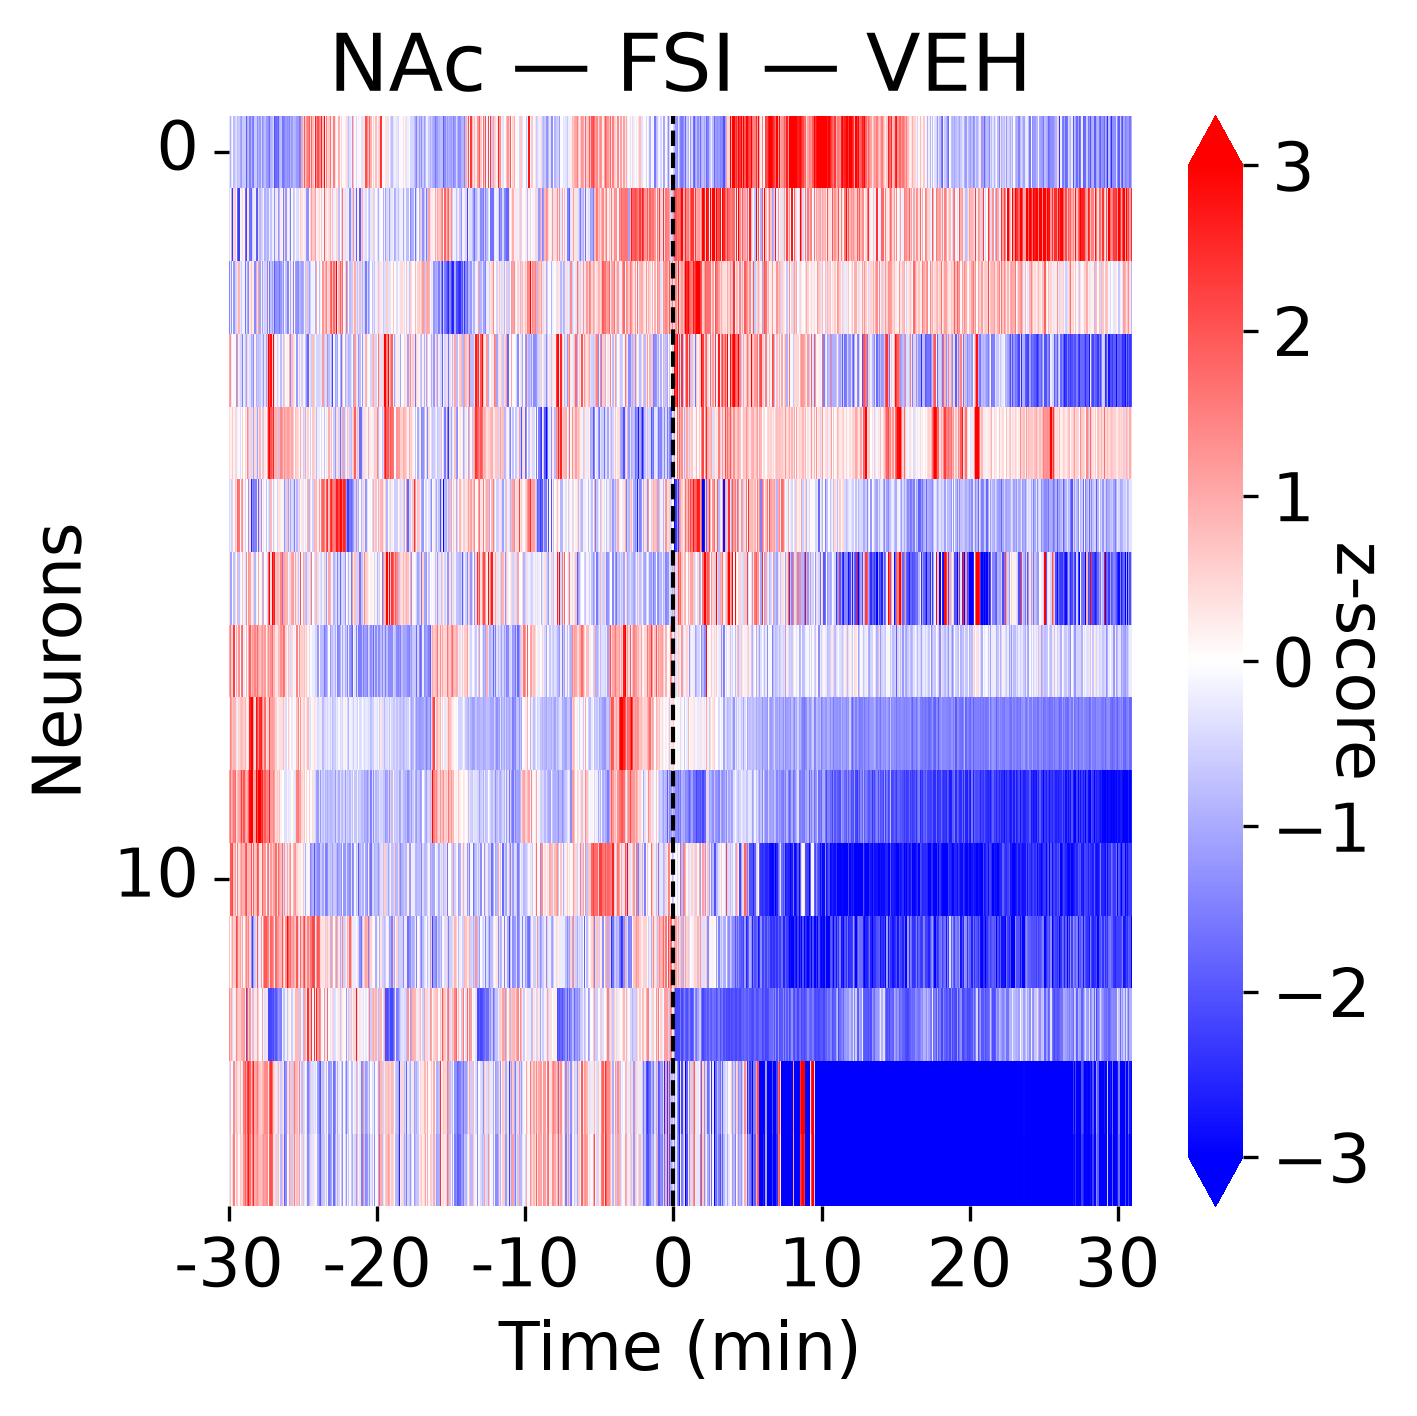

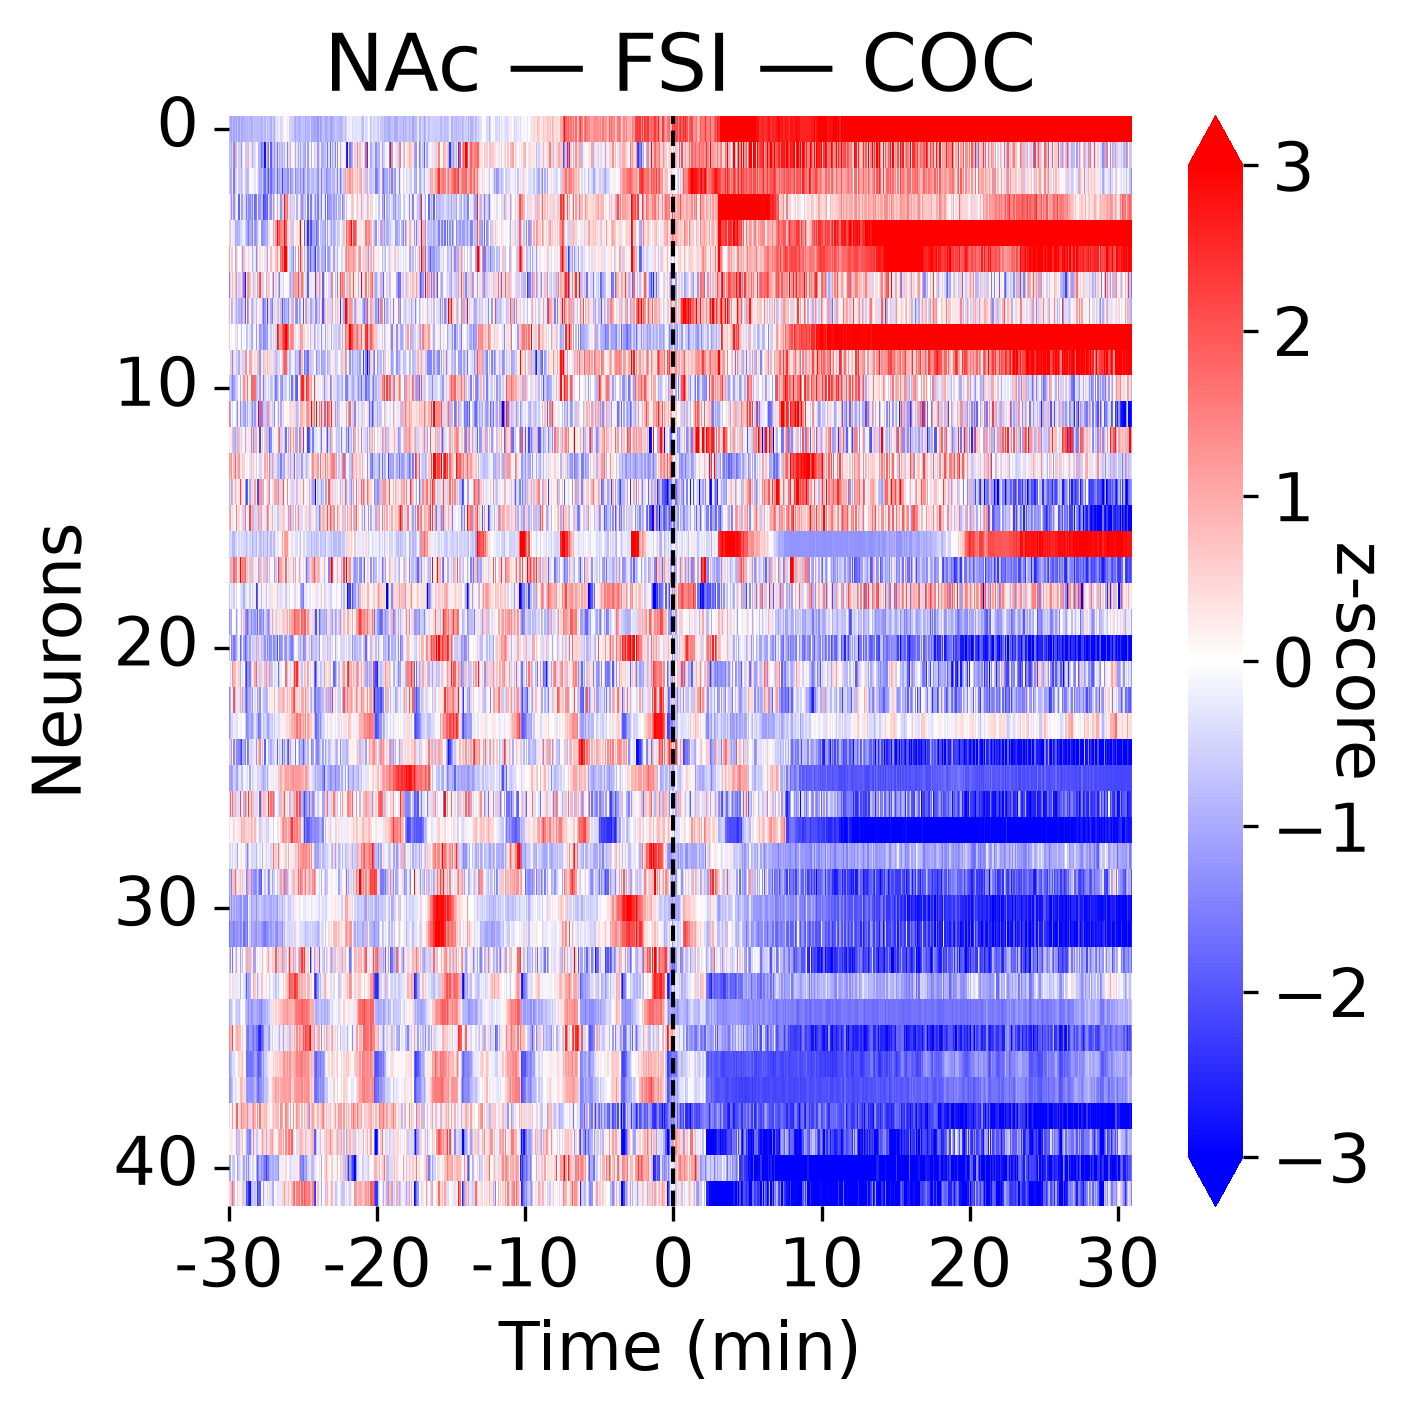

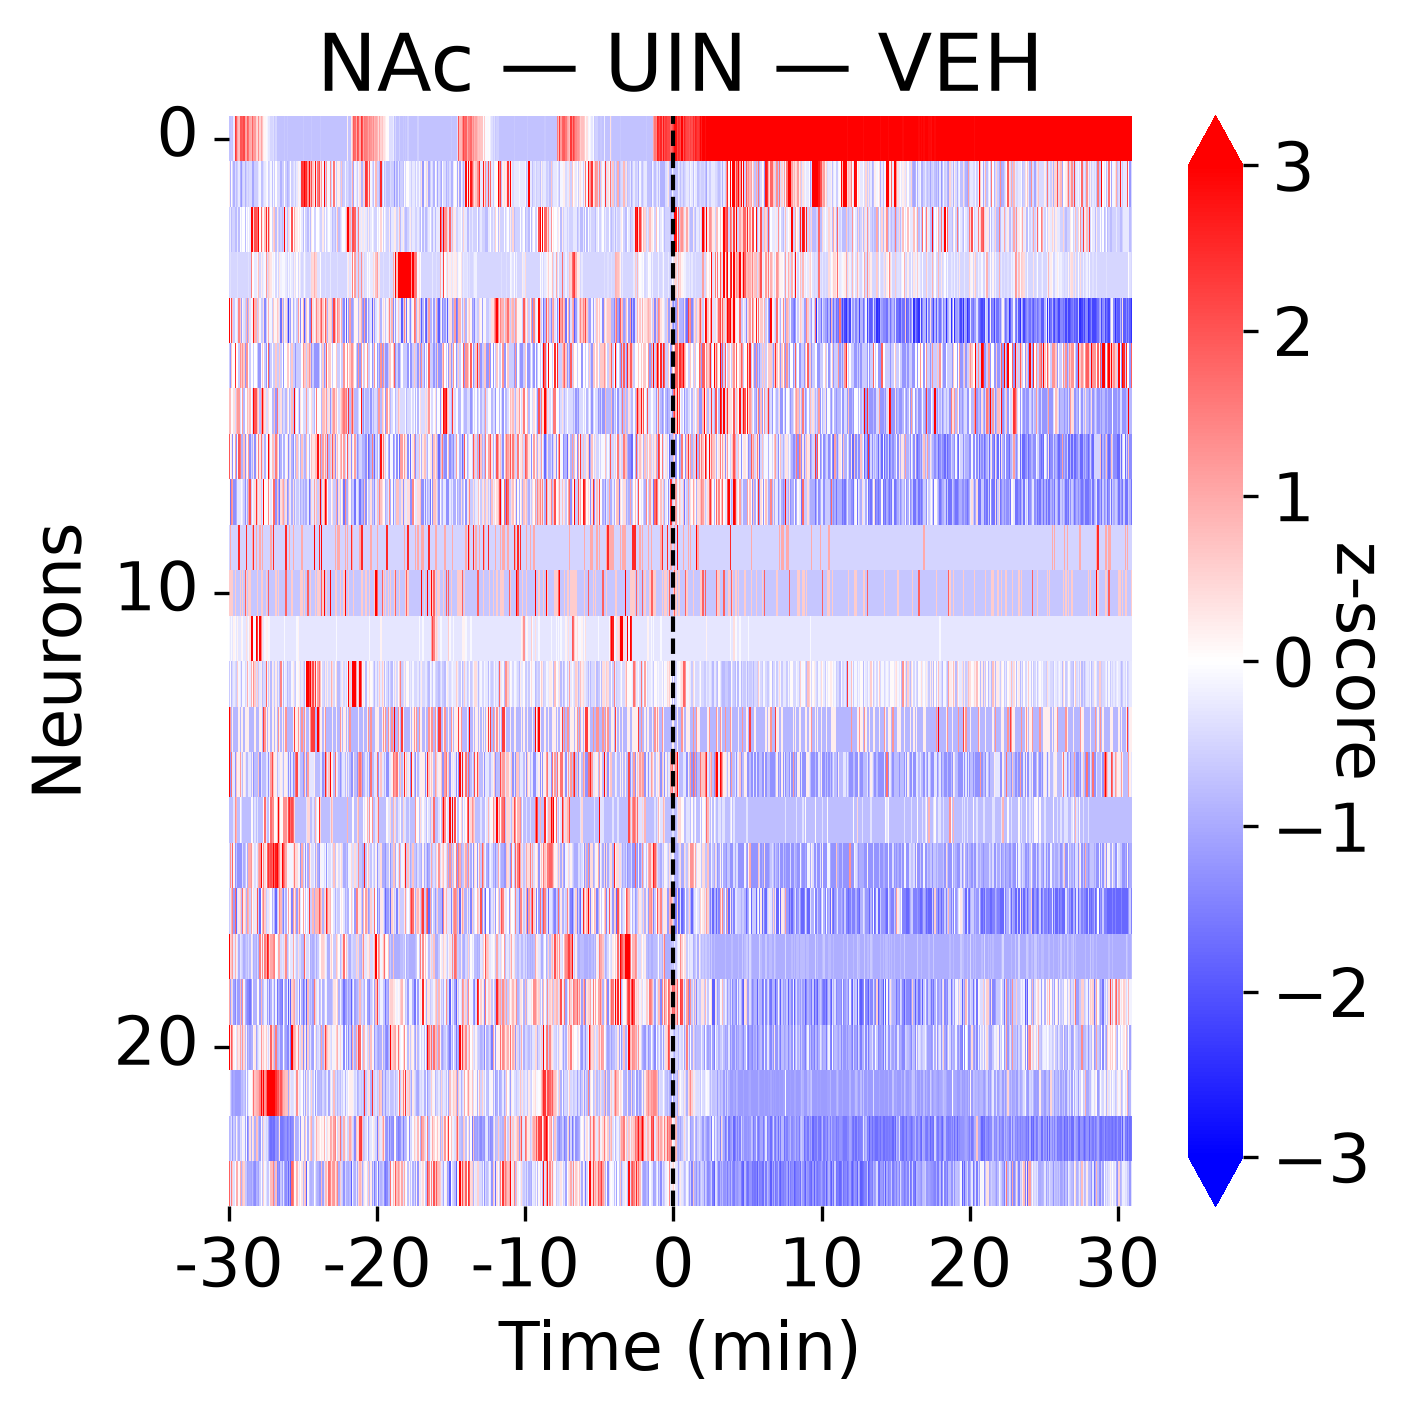

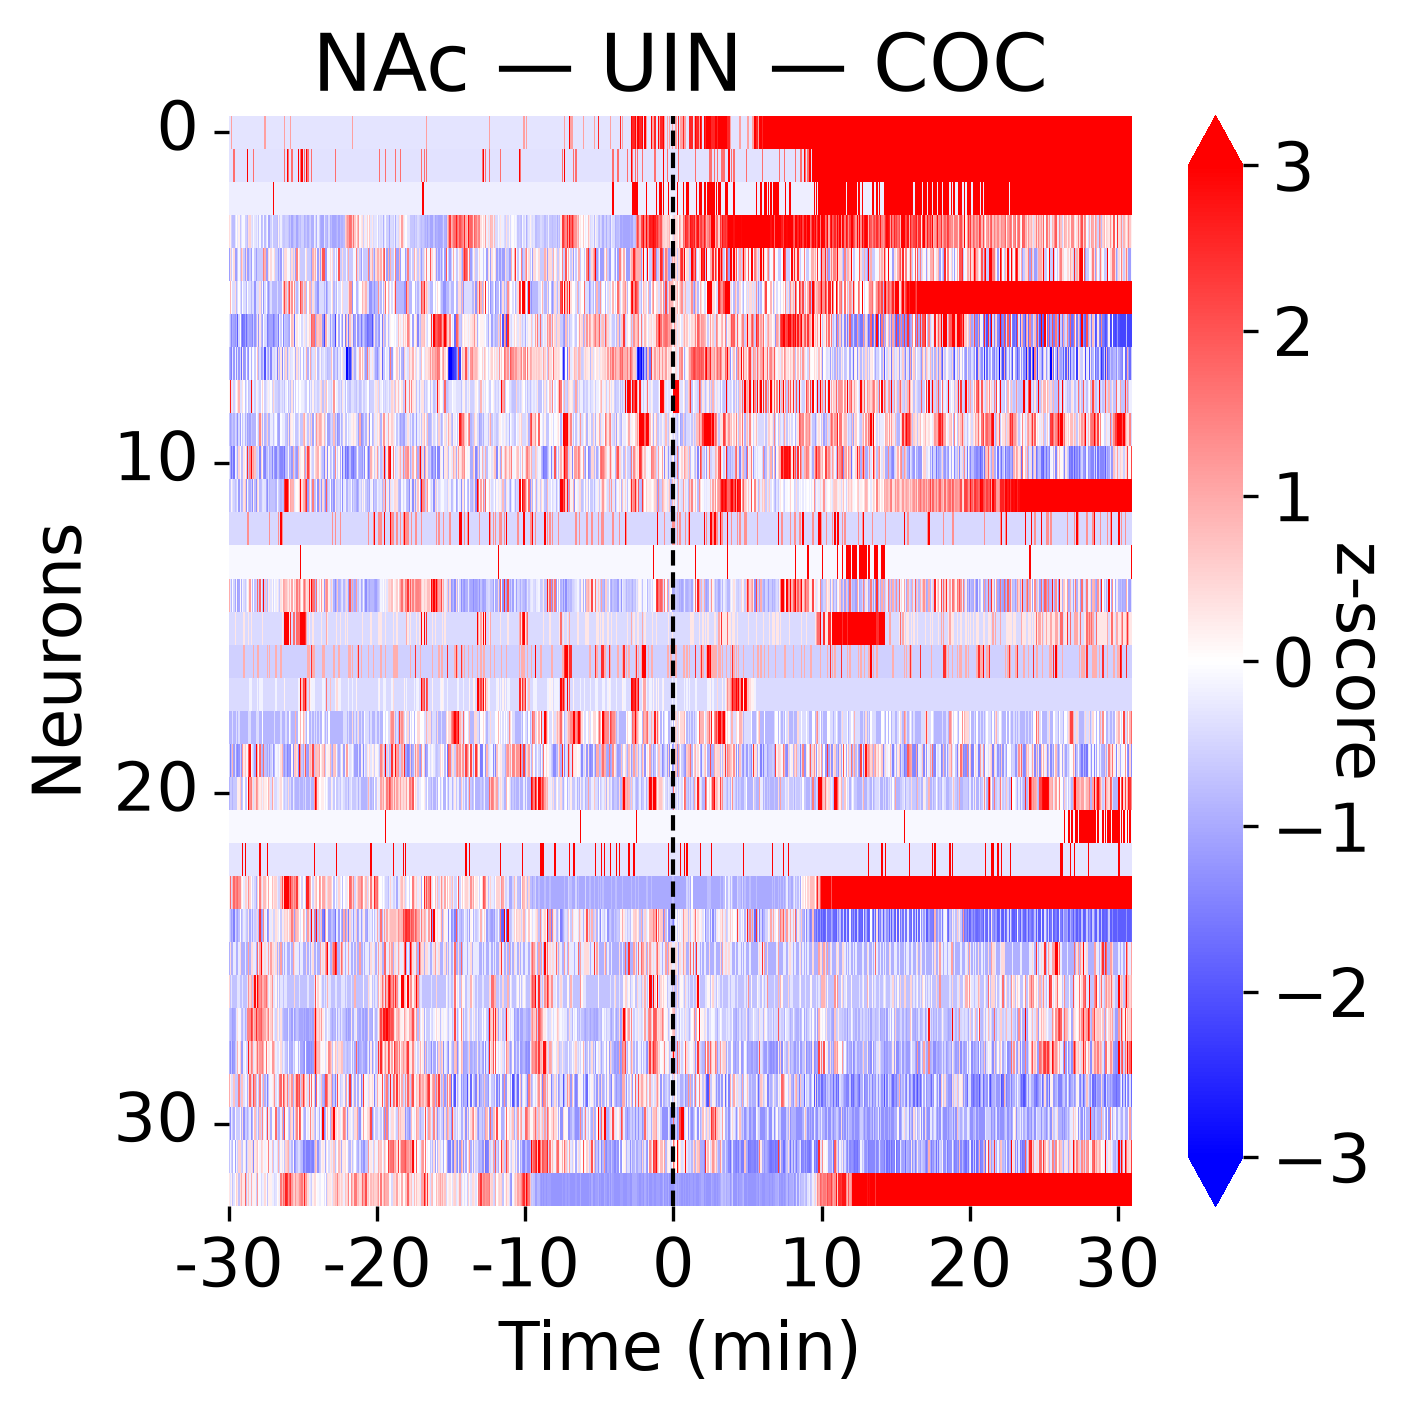

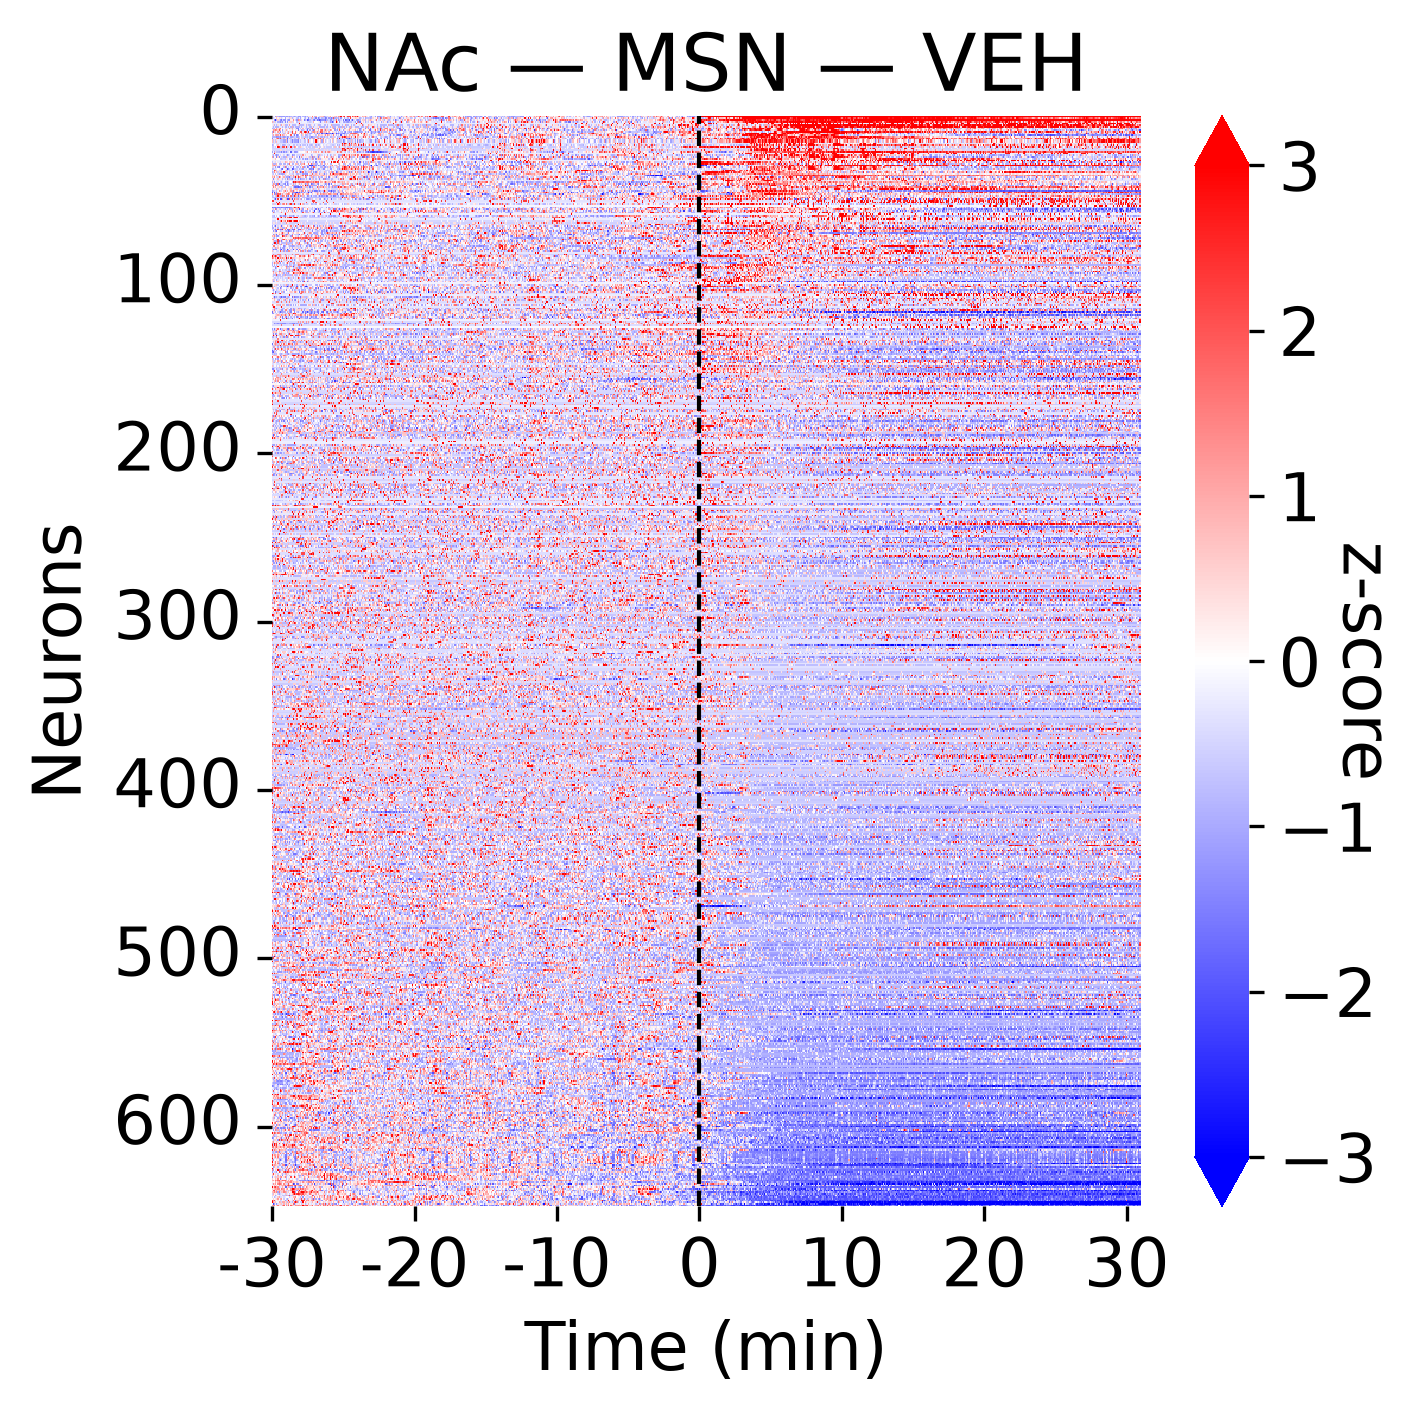

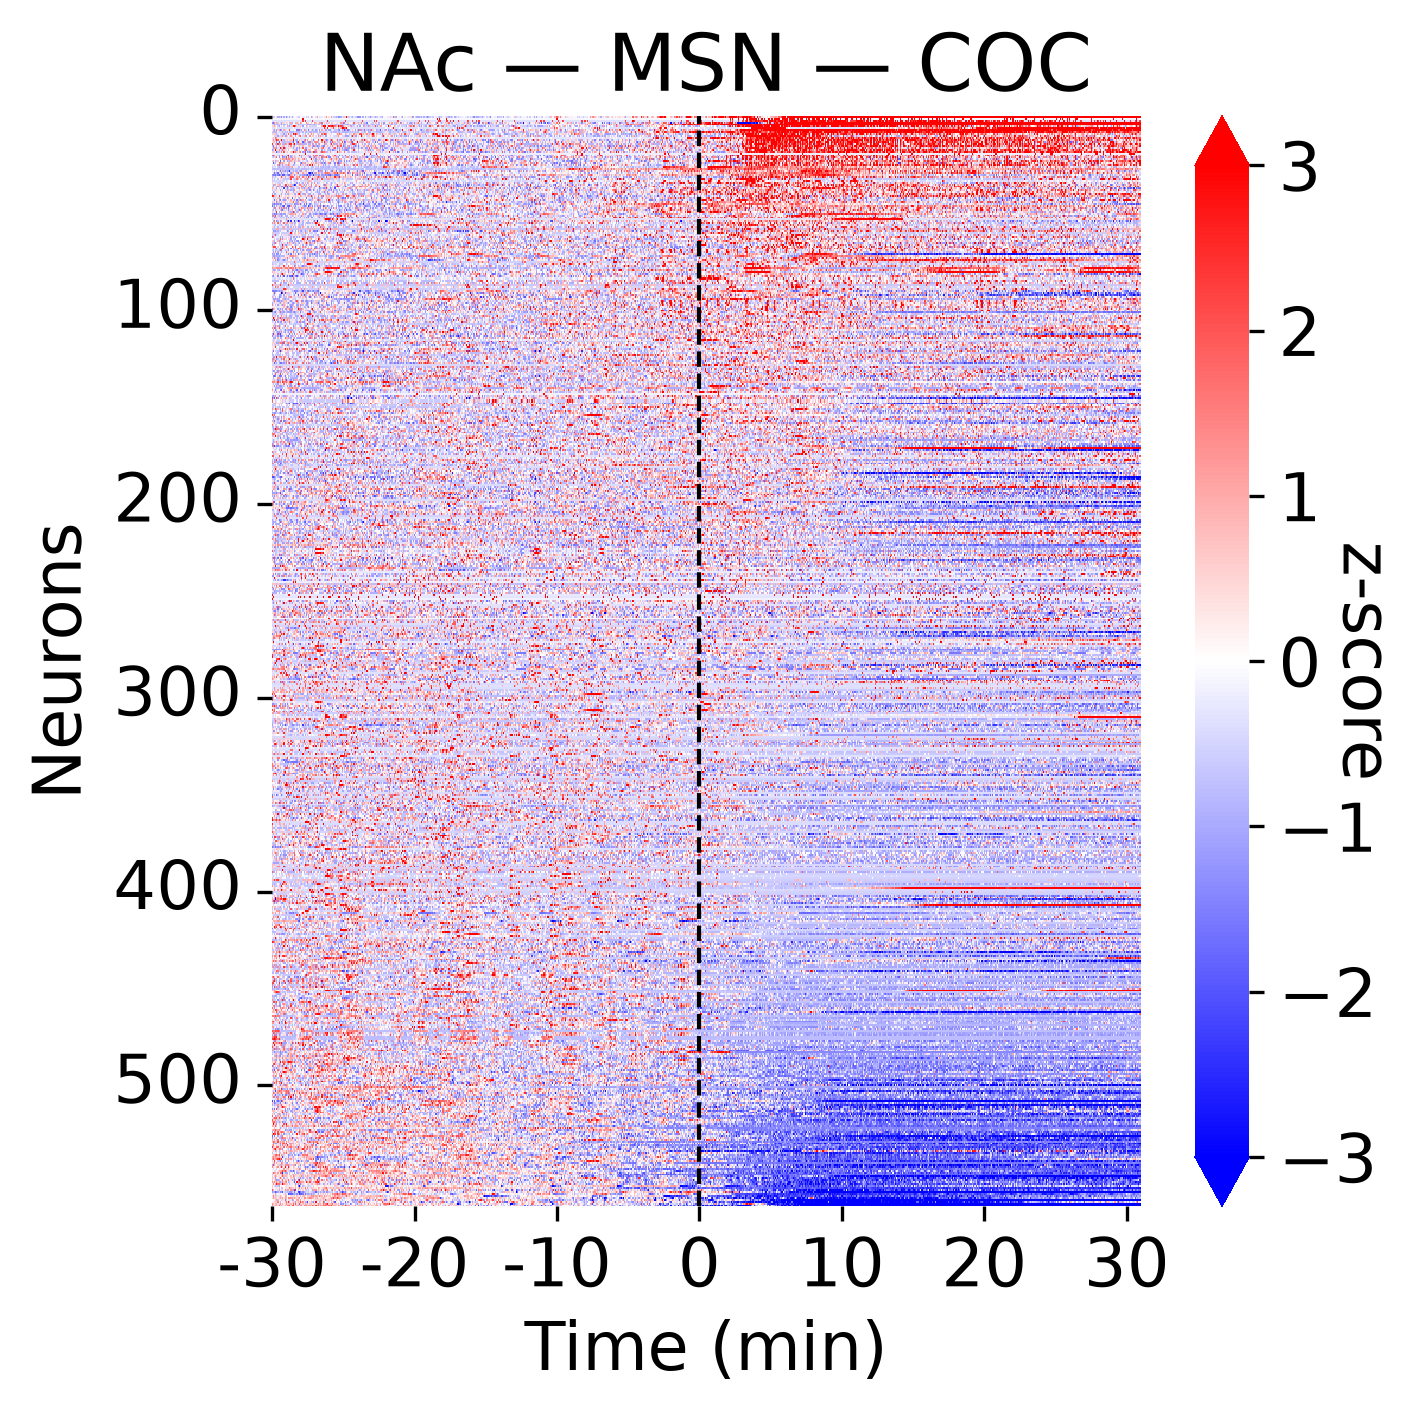

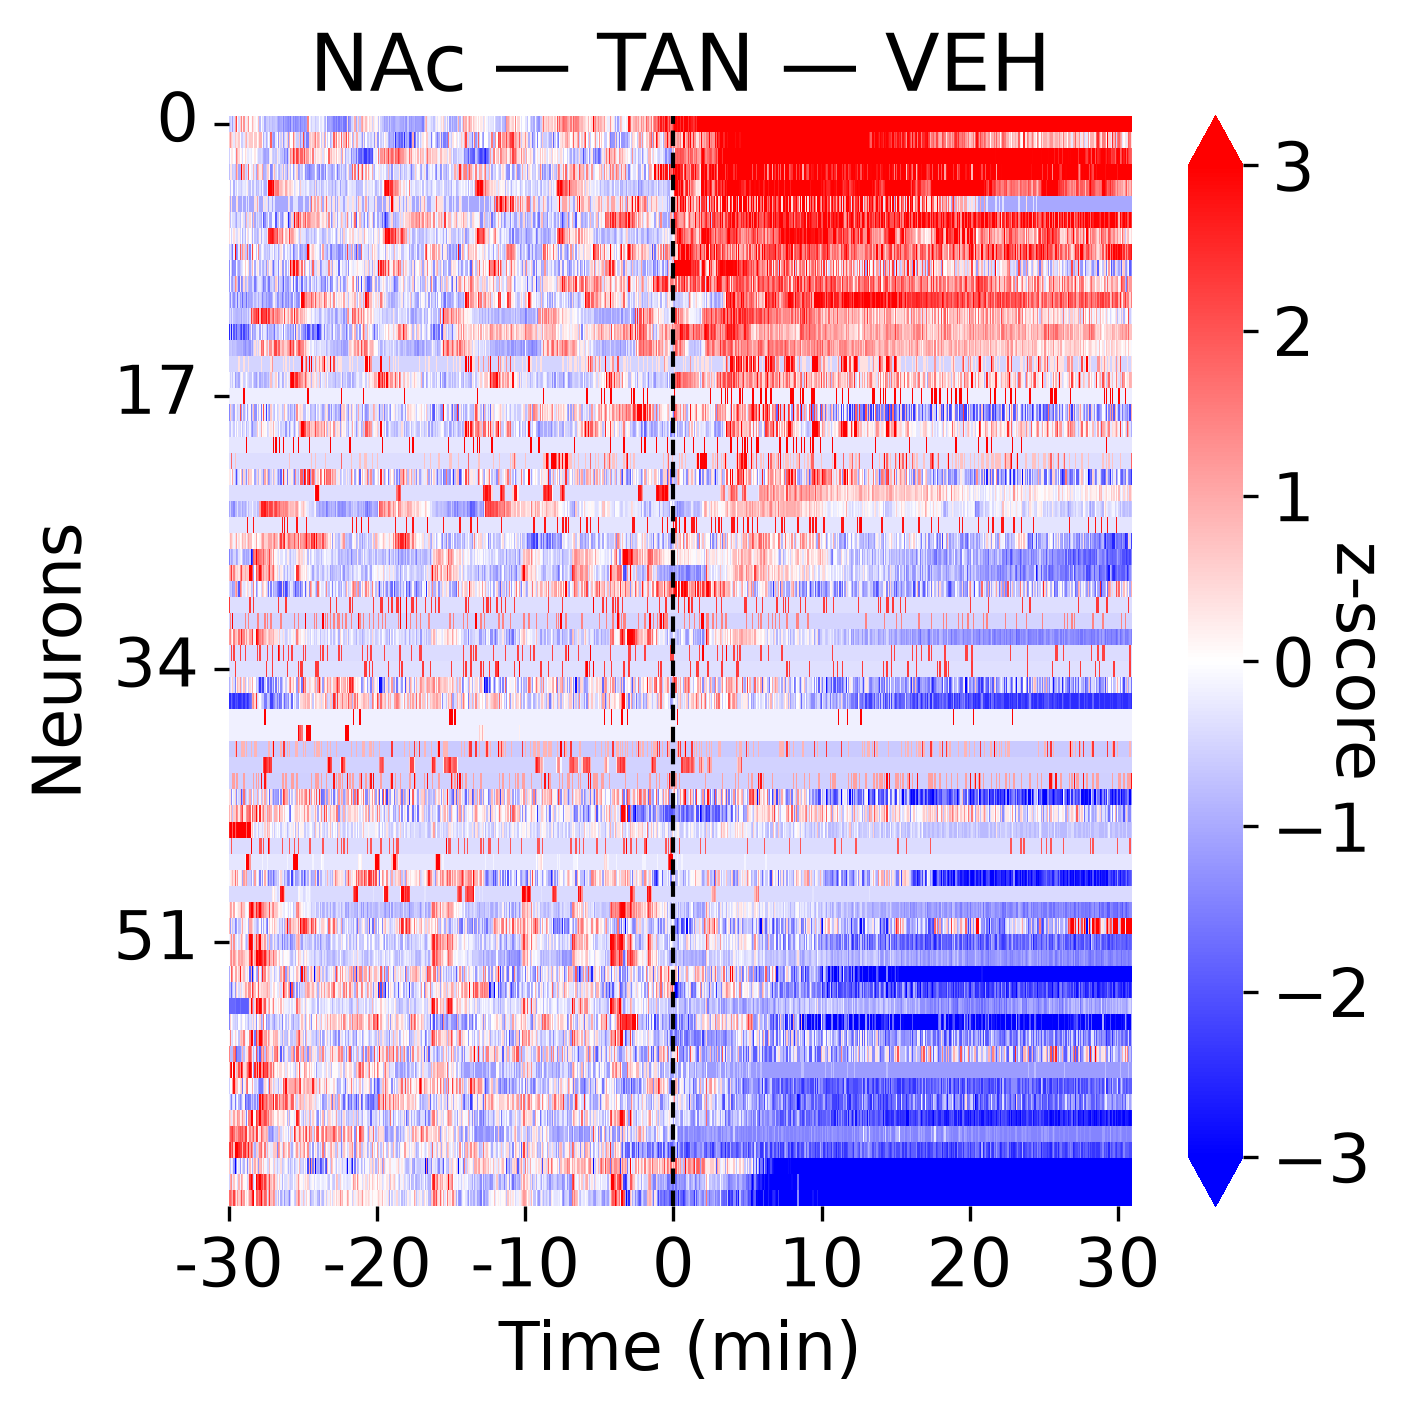

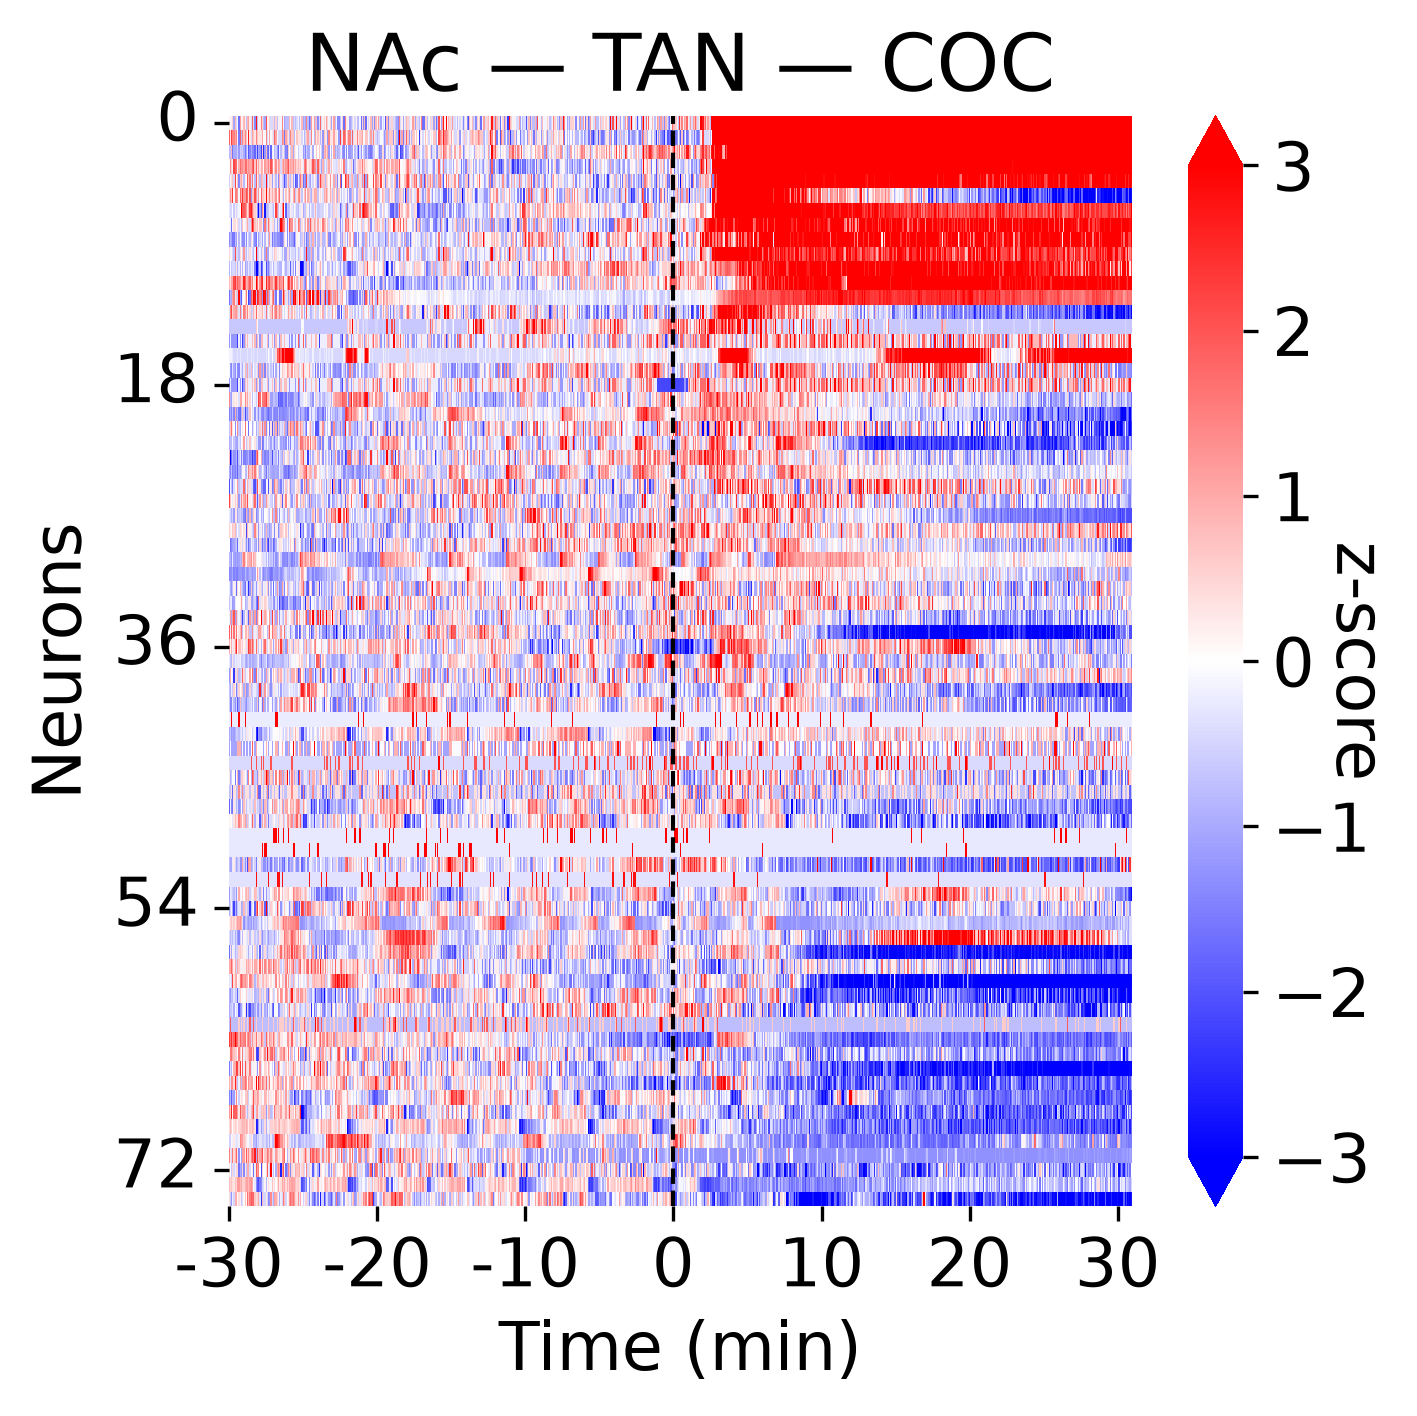

In [15]:
def plot_response_heatmap(population, group):
    """Plot baseline-normalized activity using the Figure 2 heatmap format."""
    z_scores = response_results[population][group]["z_scores"]
    if z_scores.size == 0:
        print(f"No finite z-score rows for {population} — {group}.")
        return

    window_bins = int(baseline_duration_s / bin_width_s)
    ten_minute_bins = int(10 * 60 / bin_width_s)
    response_start = z_scores.shape[1] - window_bins
    response_stop = response_start + ten_minute_bins
    sort_order = np.argsort(
        np.mean(z_scores[:, response_start:response_stop], axis=1)
    )[::-1]

    plt.figure(figsize=(5, 5), dpi=300)
    ax = sns.heatmap(
        z_scores[sort_order],
        vmin=-3,
        vmax=3,
        cmap="bwr",
        cbar_kws={"extend": "both", "label": "z-score"},
    )
    colorbar = ax.collections[0].colorbar
    colorbar.ax.yaxis.label.set_rotation(270)

    tick_step = int(10 * 60 / bin_width_s)
    tick_positions = np.arange(0, z_scores.shape[1], tick_step) + 0.5
    tick_labels = np.round(
        (np.arange(0, z_scores.shape[1], tick_step) * bin_width_s - baseline_duration_s) / 60
    ).astype(int)
    plt.xticks(tick_positions, tick_labels, rotation=0)

    neuron_tick_step = 100 if len(z_scores) >= 100 else max(10, len(z_scores) // 4)
    plt.yticks(
        np.arange(0, len(z_scores), neuron_tick_step) + 0.5,
        np.arange(0, len(z_scores), neuron_tick_step),
        rotation=0,
    )
    plt.axvline(baseline_duration_s / bin_width_s, color="black", linestyle="--", linewidth=1)
    plt.xlabel("Time (min)")
    plt.ylabel("Neurons")
    plt.title(f"{region} — {population} — {group}")
    plt.tight_layout()
    plt.show()

for population in population_masks:
    for group in group_masks:
        plot_response_heatmap(population, group)

## Percentage of response classes

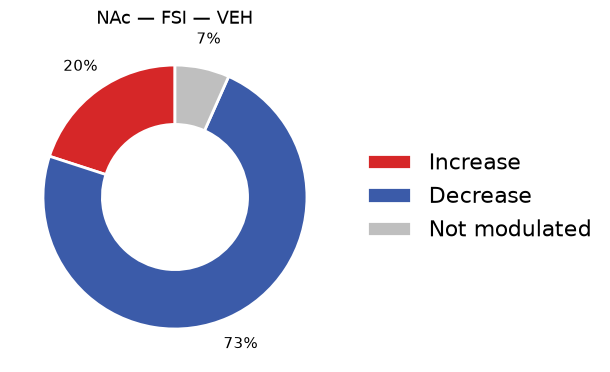

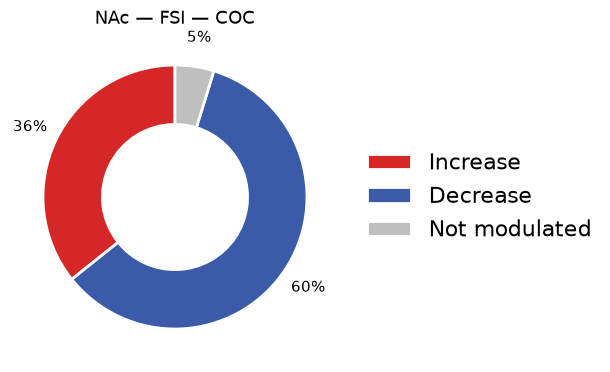

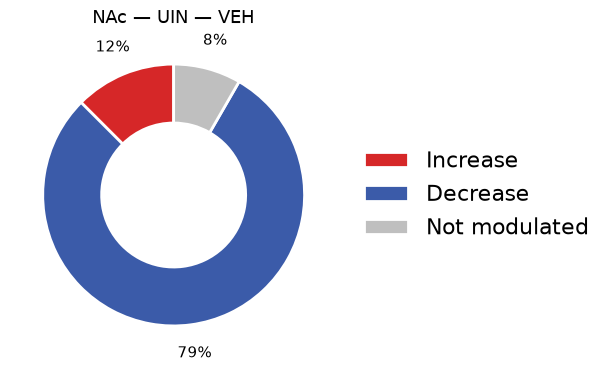

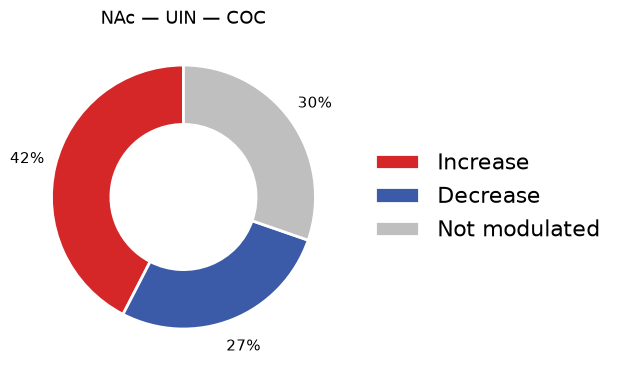

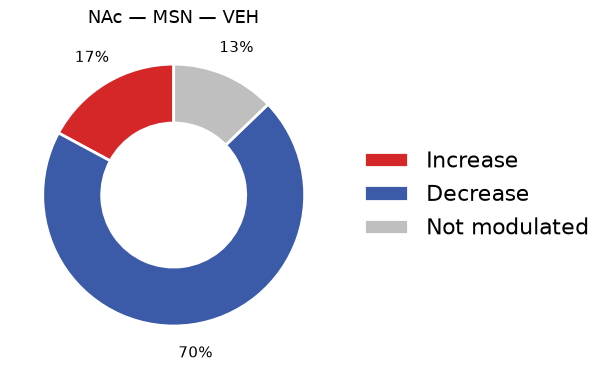

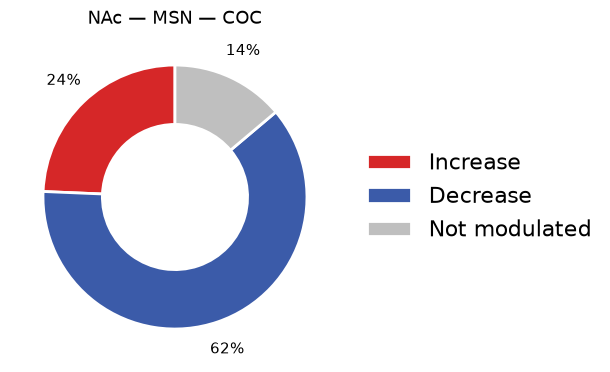

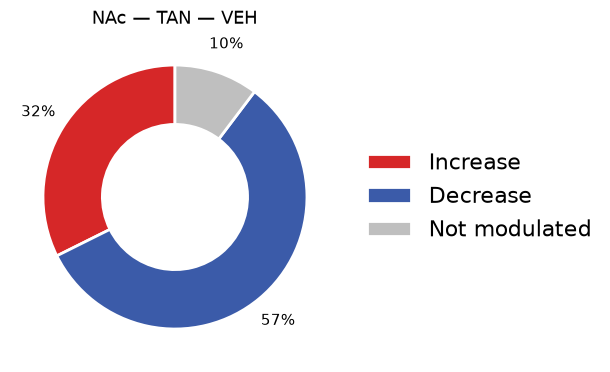

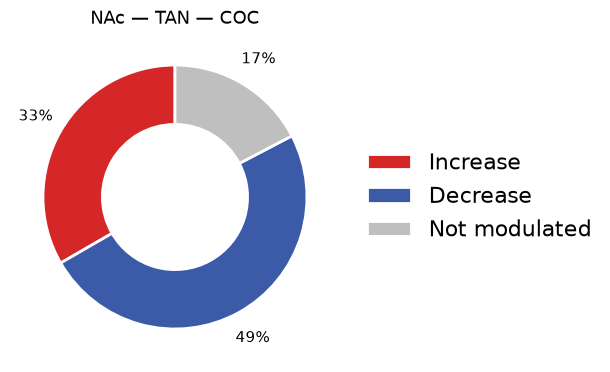

In [16]:
def plot_response_percentages(population, group):
    """Plot response percentages using the Figure 2 donut-chart format."""
    classifications = response_results[population][group]["classifications"]
    counts = collections.Counter(classifications)
    data = [counts[1], counts[-1], counts[0]]

    fig, ax = plt.subplots(figsize=(7, 4))
    wedges, _, percentage_texts = ax.pie(
        data,
        colors=response_colors,
        startangle=90,
        labels=None,
        autopct=lambda percentage: f"{percentage:.0f}%",
        pctdistance=1.22,
        wedgeprops={"width": 0.45, "edgecolor": "white", "linewidth": 2},
    )
    plt.setp(percentage_texts, fontsize=11, color="black")
    ax.set_aspect("equal")
    ax.set_title(f"{region} — {population} — {group}", fontsize=13)
    ax.legend(
        wedges,
        ["Increase", "Decrease", "Not modulated"],
        loc="center left",
        bbox_to_anchor=(1.02, 0.5),
        frameon=False,
    )
    plt.tight_layout()
    plt.show()

for population in population_masks:
    for group in group_masks:
        plot_response_percentages(population, group)